<a href="https://colab.research.google.com/github/Spacegaeguri/Drowsiness-Detection-System/blob/main/Drowsiness_Detection_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!kaggle datasets download -d ismailnasri20/driver-drowsiness-dataset-ddd

!unzip -q driver-drowsiness-dataset-ddd.zip -d dataset/

import os
print("데이터셋 준비 완료! 내부 폴더:", os.listdir('dataset'))

Dataset URL: https://www.kaggle.com/datasets/ismailnasri20/driver-drowsiness-dataset-ddd
License(s): unknown
100% 2.58G/2.58G [01:48<00:00, 25.4MB/s]

데이터셋 준비 완료! 내부 폴더: ['Driver Drowsiness Dataset (DDD)']


In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
import matplotlib.pyplot as plt

# 얼굴 전체를 인식해야 하므로 사이즈 키움
IMG_HEIGHT = 128
IMG_WIDTH = 128
BATCH_SIZE = 32
EPOCHS = 15

# 데이터셋 폴더 구조에 맞춰 경로 수정
TRAIN_DIR = 'dataset/Driver Drowsiness Dataset (DDD)'

In [ ]:
# 다양한 주행 환경을 시뮬레이션하기 위한 증강 세팅
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,           # 고개가 기울어지는 상황 대비
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.1,
    brightness_range=[0.7, 1.3], # 터널, 야간, 주간 빛 변화 대비
    validation_split=0.2
)

# 컬러 이미지(rgb)로 학습
train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='training',
    color_mode='rgb'             # 색상 정보 포함
)

validation_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='validation',
    color_mode='rgb'
)

# 모델이 어떤 번호를 매겼는지 확인
print("\n클래스 매핑 결과:", train_generator.class_indices)

Found 33435 images belonging to 2 classes.
Found 8358 images belonging to 2 classes.

클래스 매핑 결과: {'Drowsy': 0, 'Non Drowsy': 1}


In [22]:
gitignore_content = """dataset/
*.h5
*.pt
runs/
__pycache__/
.DS_Store
"""

with open('.gitignore', 'w') as f:
    f.write(gitignore_content)

print('.gitignore 파일이 최상단에 생성되었습니다.')
!cat .gitignore

.gitignore 파일이 최상단에 생성되었습니다.
dataset/
*.h5
*.pt
runs/
__pycache__/
.DS_Store


In [ ]:
model = Sequential([
    # Input shape의 마지막을 3(컬러)으로 변경
    Conv2D(32, (3, 3), activation='relu', input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

얼굴 기반 졸음 감지 학습을 시작합니다!
Epoch 1/15
1045/1045 ━━━━━━━━━━━━━━━━━━━━ 1034s 985ms/step - accuracy: 0.8765 - loss: 0.2533 - val_accuracy: 0.5700 - val_loss: 2.7736
Epoch 2/15
1045/1045 ━━━━━━━━━━━━━━━━━━━━ 1137s 1s/step - accuracy: 0.9844 - loss: 0.0495 - val_accuracy: 0.6006 - val_loss: 2.0915
Epoch 3/15
1045/1045 ━━━━━━━━━━━━━━━━━━━━ 1065s 1s/step - accuracy: 0.9911 - loss: 0.0271 - val_accuracy: 0.5543 - val_loss: 3.4204
Epoch 4/15
1045/1045 ━━━━━━━━━━━━━━━━━━━━ 1107s 1s/step - accuracy: 0.9911 - loss: 0.0287 - val_accuracy: 0.5609 - val_loss: 3.1799
Epoch 5/15
1045/1045 ━━━━━━━━━━━━━━━━━━━━ 1108s 1s/step - accuracy: 0.9944 - loss: 0.0183 - val_accuracy: 0.5840 - val_loss: 3.0722
Epoch 6/15
1045/1045 ━━━━━━━━━━━━━━━━━━━━ 1165s 1s/step - accuracy: 0.9946 - loss: 0.0179 - val_accuracy: 0.5891 - val_loss: 2.5579
Epoch 7/15
1045/1045 ━━━━━━━━━━━━━━━━━━━━ 1099s 1s/step - accuracy: 0.9958 - loss: 0.0149 - val_accuracy: 0.6363 - val_loss: 3.4313
Epoch 8/15
1045/1045 ━━━━━━━━━━━━━━━━━━━━ 1052s 1s

모델 저장 완료!

테스트할 얼굴 사진(눈을 감거나 뜬 사진)을 업로드해주세요.


Saving images1.jpg to images1.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 442ms/step


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51320 (\N{HANGUL SYLLABLE JOL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51020 (\N{HANGUL SYLLABLE EUM}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 53468 (\N{HANGUL SYLLABLE TAE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


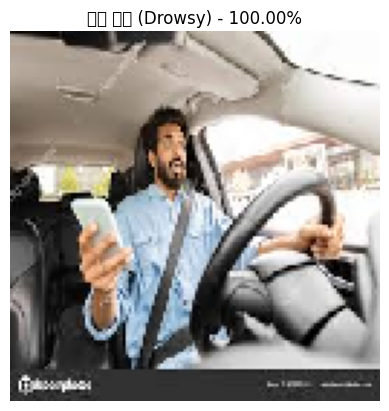

최종 예측: 졸음 상태 (Drowsy) - 100.00%


In [ ]:
print("얼굴 기반 졸음 감지 학습을 시작합니다!")
history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=validation_generator
)

model.save('drowsiness_face_model.h5')
print("모델 저장 완료!")


테스트할 얼굴 사진(눈을 감거나 뜬 사진)을 업로드해주세요.


Saving images11.jpg to images11.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step


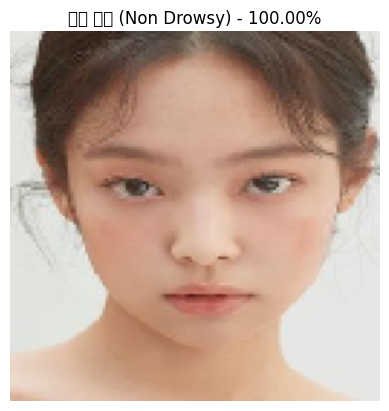

최종 예측: 각성 상태 (Non Drowsy) - 100.00%


In [21]:
# ==========================================
# 내 사진으로 테스트해보기 (사진 업로드)
# ==========================================
from google.colab import files
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt

print('\n테스트할 얼굴 사진(눈을 감거나 뜬 사진)을 업로드해주세요.')
uploaded = files.upload()

for fn in uploaded.keys():
    img = image.load_img(fn, target_size=(IMG_HEIGHT, IMG_WIDTH), color_mode='rgb')
    x = image.img_to_array(img)
    x = x / 255.0
    x = np.expand_dims(x, axis=0)

    prediction = model.predict(x)

    plt.imshow(img)
    plt.axis('off')

    # 클래스 매핑: {'Drowsy': 0, 'Non Drowsy': 1}
    if prediction[0] > 0.5:
        result = f"각성 상태 (Non Drowsy) - {(prediction[0][0])*100:.2f}%"
    else:
        result = f"졸음 상태 (Drowsy) - {(1-prediction[0][0])*100:.2f}%"

    plt.title(result)
    plt.show()
    print(f"최종 예측: {result}")